# Análisis estadístico mejorado — Online Food Delivery

Este notebook amplía la primera versión del análisis con una metodología más rigurosa para **buscar patrones, medir la fuerza de las relaciones y separar asociación de causalidad**.

La mejora principal es que no nos limitamos a observar porcentajes. Para cada tipo de variable usamos una medida apropiada:

- **Categórica ↔ categórica:** chi-cuadrado / Fisher + **V de Cramér corregida**.
- **Numérica ↔ numérica:** **correlación de Spearman**.
- **Categórica ↔ numérica:** **correlation ratio (η)**.
- **Numérica ↔ Output binario:** **Mann–Whitney U**, tamaño de efecto **rank-biserial** y bootstrap.
- **Varias variables simultáneamente:** regresión logística exploratoria para comprobar si los patrones bivariados persisten al ajustar por otras variables.
- **Múltiples pruebas:** corrección de **Holm** para reducir falsos positivos.

> Importante: el dataset es observacional. Una asociación estadística no demuestra causalidad.

## 1. Librerías y configuración

Se cargan las herramientas necesarias para manipulación, visualización y pruebas estadísticas. Se usa `matplotlib` sin estilos externos para reducir problemas de compatibilidad en editores online.

In [1]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, spearmanr
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
RANDOM_STATE = 42

## 2. Carga portable del archivo

El notebook busca el CSV en varias rutas comunes. Esto permite ejecutarlo tanto en Kaggle como en un editor local o en otro notebook online sin tener que cambiar manualmente la ruta en cada entorno.

In [2]:
candidatos = [
    Path('/kaggle/working/online_food_delivery_limpio.csv'),
    Path('/mnt/data/online_food_delivery_limpio.csv'),
    Path('online_food_delivery_limpio.csv'),
]

ruta = next((p for p in candidatos if p.exists()), None)
if ruta is None:
    raise FileNotFoundError(
        'No se encontró online_food_delivery_limpio.csv. '
        'Coloca el archivo junto al notebook o en /kaggle/working/.'
    )

raw = pd.read_csv(ruta)
print('Archivo:', ruta)
print(f'Filas originales: {raw.shape[0]} | Columnas originales: {raw.shape[1]}')
display(raw.head())

Archivo: /mnt/data/online_food_delivery_limpio.csv
Filas originales: 388 | Columnas originales: 14


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


## 3. Auditoría de calidad de datos

Antes de medir relaciones se comprueba:

1. tipos de datos;
2. valores nulos;
3. duplicados exactos;
4. columnas redundantes;
5. espacios accidentales en variables categóricas.

Esto es importante porque un duplicado puede inflar frecuencias y una columna que copia la variable objetivo puede generar **data leakage**.

In [3]:
resumen_calidad = pd.DataFrame({
    'tipo': raw.dtypes.astype(str),
    'nulos': raw.isna().sum(),
    'n_unicos': raw.nunique(dropna=False),
})

duplicados = int(raw.duplicated().sum())
print('Duplicados exactos:', duplicados)
display(resumen_calidad)

Duplicados exactos: 103


,tipo,nulos,n_unicos
Age,int64,0,16
Gender,object,0,2
Marital Status,object,0,3
Occupation,object,0,4
Monthly Income,object,0,5
Educational Qualifications,object,0,5
Family size,int64,0,6
Customer Type,object,0,3
latitude,float64,0,77
longitude,float64,0,76


In [4]:
# Normalización mínima: solo se eliminan espacios al inicio/final de strings.
df = raw.copy()
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Comprobar si Unnamed: 13 replica Output.
if {'Unnamed: 13', 'Output'}.issubset(df.columns):
    coincidencia = (df['Unnamed: 13'].astype(str) == df['Output'].astype(str)).mean()
    print(f'Coincidencia entre Unnamed: 13 y Output: {coincidencia:.1%}')
else:
    coincidencia = np.nan

# Deduplicar antes del análisis inferencial.
df = df.drop_duplicates().copy()

# Eliminar la columna redundante si coincide exactamente con Output.
if 'Unnamed: 13' in df.columns and coincidencia == 1:
    df = df.drop(columns='Unnamed: 13')

print(f'Registros únicos usados: {len(df)}')
print(f'Columnas usadas: {df.shape[1]}')

Coincidencia entre Unnamed: 13 y Output: 100.0%
Registros únicos usados: 285
Columnas usadas: 13


### Interpretación de calidad

En el archivo actual se detectan **103 duplicados exactos**. Después de retirarlos quedan **285 observaciones únicas**. Además, `Unnamed: 13` reproduce exactamente `Output`, por lo que se elimina: incluirla en asociaciones o modelos haría que el resultado pareciera artificialmente perfecto.

La limpieza de espacios convierte, por ejemplo, `"Negative "` en `"Negative"` sin modificar el significado original.

## 4. Clasificación conceptual de variables

No todas las columnas numéricas deben analizarse como medidas continuas. `Pin code` es un identificador geográfico aunque esté almacenado como número. `latitude` y `longitude` son coordenadas y se analizan por separado.

Para el análisis estadístico principal usamos:

- **Numéricas:** `Age`, `Family size`.
- **Categóricas:** género, estado civil, ocupación, ingreso, educación, tipo de cliente, feedback y output.
- **Geográficas:** latitude, longitude, Pin code.

In [5]:
numericas = ['Age', 'Family size']
categoricas_predictoras = [
    'Gender', 'Marital Status', 'Occupation', 'Monthly Income',
    'Educational Qualifications', 'Customer Type', 'Feedback'
]
categoricas_todas = categoricas_predictoras + ['Output']
geograficas = ['latitude', 'longitude', 'Pin code']

print('Numéricas:', numericas)
print('Categóricas:', categoricas_todas)
print('Geográficas:', geograficas)

Numéricas: ['Age', 'Family size']
Categóricas: ['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Customer Type', 'Feedback', 'Output']
Geográficas: ['latitude', 'longitude', 'Pin code']


## 5. Estadística descriptiva y distribución de `Output`

La estadística descriptiva permite entender escala, centro y dispersión antes de aplicar pruebas. La distribución de `Output` también indica si existe desbalance entre `Yes` y `No`.

,count,mean,std,min,25%,50%,75%,max
Age,285.0000,24.6772,3.0410,18.0000,23.0000,24.0000,26.0000,33.0000
Family size,285.0000,3.2702,1.3612,1.0000,2.0000,3.0000,4.0000,6.0000


,conteo,porcentaje
Output,,
Yes,217,76.1400
No,68,23.8600


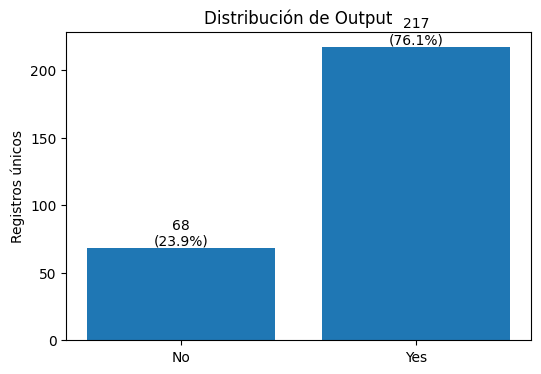

In [6]:
display(df[numericas].describe().T)

output_dist = df['Output'].value_counts().to_frame('conteo')
output_dist['porcentaje'] = output_dist['conteo'] / len(df) * 100
display(output_dist.round(2))

fig, ax = plt.subplots(figsize=(6,4))
counts = df['Output'].value_counts().reindex(['No','Yes']).dropna()
ax.bar(counts.index, counts.values)
ax.set_title('Distribución de Output')
ax.set_ylabel('Registros únicos')
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v}\n({v/len(df):.1%})', ha='center', va='bottom')
plt.show()

## 6. Detección de valores atípicos con IQR

El criterio IQR marca como potencialmente atípicos los valores fuera de:

\[
[Q1 - 1.5	imes IQR,\; Q3 + 1.5	imes IQR]
\]

**No se eliminan automáticamente.** Un valor atípico puede ser perfectamente válido; primero debe evaluarse en contexto.

In [7]:
outliers = []
for col in numericas:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (df[col] < li) | (df[col] > ls)
    outliers.append({
        'variable': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'limite_inferior': li, 'limite_superior': ls,
        'n_outliers_IQR': int(mask.sum()),
        'pct_outliers': mask.mean()*100
    })
display(pd.DataFrame(outliers).round(3))

,variable,Q1,Q3,IQR,limite_inferior,limite_superior,n_outliers_IQR,pct_outliers
0,Age,23.0000,26.0000,3.0000,18.5000,30.5000,21,7.3680
1,Family size,2.0000,4.0000,2.0000,-1.0000,7.0000,0,0.0000


### Lectura de outliers

`Age` produce algunos valores fuera del rango IQR, pero las edades siguen dentro de un rango humano plausible del dataset. Por eso se mantienen. `Family size` no presenta outliers bajo este criterio.

Esto ilustra por qué **outlier no significa error**.

## 7. Variables numéricas vs `Output`

### ¿Por qué Mann–Whitney U?

`Age` y `Family size` son discretas y no necesitamos asumir normalidad. Mann–Whitney compara la posición de las distribuciones de dos grupos (`Yes` vs `No`).

Además del p-value calculamos **rank-biserial correlation**, un tamaño de efecto entre -1 y 1:

- signo negativo: los valores tienden a ser menores en `Yes`;
- signo positivo: tienden a ser mayores en `Yes`;
- cerca de 0: poca separación entre grupos.

También usamos **bootstrap** para construir un intervalo de confianza de la diferencia de medias. Esto ayuda a cuantificar incertidumbre, no solo significancia.

In [8]:
def bootstrap_mean_diff(a, b, n_boot=5000, seed=42):
    rng = np.random.default_rng(seed)
    a = np.asarray(a)
    b = np.asarray(b)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, len(a), replace=True)
        sb = rng.choice(b, len(b), replace=True)
        diffs[i] = sa.mean() - sb.mean()
    return np.quantile(diffs, [0.025, 0.975])

def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    m = len(pvalues)
    order = np.argsort(pvalues)
    adjusted = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        val = (m-rank) * pvalues[idx]
        running = max(running, val)
        adjusted[idx] = min(running, 1.0)
    return adjusted

resultados_num = []
for col in numericas:
    yes = df.loc[df['Output']=='Yes', col].to_numpy()
    no = df.loc[df['Output']=='No', col].to_numpy()
    U, p = mannwhitneyu(yes, no, alternative='two-sided')
    r_rb = 2*U/(len(yes)*len(no)) - 1
    ci_lo, ci_hi = bootstrap_mean_diff(yes, no, seed=RANDOM_STATE)
    resultados_num.append({
        'variable': col,
        'media_Yes': yes.mean(),
        'media_No': no.mean(),
        'dif_media_Yes_menos_No': yes.mean()-no.mean(),
        'mediana_Yes': np.median(yes),
        'mediana_No': np.median(no),
        'U': U,
        'p_value': p,
        'rank_biserial': r_rb,
        'IC95_dif_media_inf': ci_lo,
        'IC95_dif_media_sup': ci_hi,
    })

res_num = pd.DataFrame(resultados_num)
res_num['p_Holm'] = holm_adjust(res_num['p_value'])
display(res_num.round(4))

,variable,media_Yes,media_No,dif_media_Yes_menos_No,mediana_Yes,mediana_No,U,p_value,rank_biserial,IC95_dif_media_inf,IC95_dif_media_sup,p_Holm
0,Age,24.2949,25.8971,-1.6021,24.0000,26.0000,"4,754.5000",0.0000,-0.3556,-2.4085,-0.7954,0.0000
1,Family size,3.2396,3.3676,-0.1280,3.0000,3.0000,"7,237.5000",0.8083,-0.0190,-0.5376,0.2822,0.8083


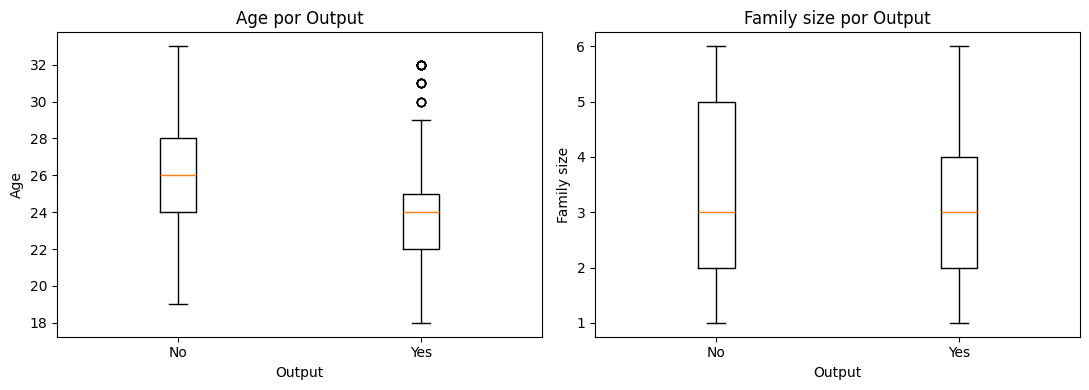

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, col in zip(axes, numericas):
    groups = [
        df.loc[df['Output']=='No', col],
        df.loc[df['Output']=='Yes', col]
    ]
    ax.boxplot(groups, labels=['No','Yes'])
    ax.set_title(f'{col} por Output')
    ax.set_xlabel('Output')
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

### Interpretación numérica

En este dataset, `Age` sí presenta una diferencia estadísticamente clara entre `Yes` y `No`, y el tamaño de efecto rank-biserial indica una separación **moderada** en dirección negativa: el grupo `Yes` tiende a ser más joven. El intervalo bootstrap de la diferencia media no cruza 0.

`Family size`, en cambio, muestra un tamaño de efecto prácticamente nulo y un p-value alto. Por sí sola no parece explicar `Output`.

## 8. Variables categóricas vs `Output`: chi-cuadrado, Fisher y V de Cramér

El **chi-cuadrado de independencia** responde si dos variables categóricas están asociadas, pero el p-value no indica qué tan fuerte es esa asociación.

Por eso añadimos **V de Cramér corregida por sesgo**:

\[
V \in [0,1]
\]

- 0 implica ausencia de asociación observada;
- valores mayores indican una relación más fuerte.

También revisamos los **conteos esperados** del chi-cuadrado. Si demasiadas celdas tienen esperados menores a 5, el p-value debe interpretarse con precaución. Para tablas 2×2 calculamos además **Fisher exacto**.

Finalmente aplicamos la corrección **Holm** sobre los p-values categóricos para controlar el error por realizar varias pruebas simultáneamente.

In [10]:
def cramers_v_bias_corrected(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    denom = min(kcorr-1, rcorr-1)
    return np.sqrt(phi2corr/denom) if denom > 0 else 0.0

filas = []
for col in categoricas_predictoras:
    tabla = pd.crosstab(df[col], df['Output'])
    chi2, p, dof, expected = chi2_contingency(tabla, correction=False)
    fisher_p = np.nan
    fisher_or = np.nan
    if tabla.shape == (2,2):
        fisher_or, fisher_p = fisher_exact(tabla.to_numpy())
    filas.append({
        'variable': col,
        'chi2': chi2,
        'gl': dof,
        'p_value_chi2': p,
        'V_Cramer_corregida': cramers_v_bias_corrected(df[col], df['Output']),
        'min_esperado': expected.min(),
        'pct_celdas_esperado_menor_5': (expected < 5).mean()*100,
        'Fisher_OR_si_2x2': fisher_or,
        'Fisher_p_si_2x2': fisher_p,
    })

res_cat = pd.DataFrame(filas)
res_cat['p_Holm'] = holm_adjust(res_cat['p_value_chi2'])
res_cat['supuesto_chi2'] = np.where(
    res_cat['pct_celdas_esperado_menor_5'] > 20,
    'Precaución (>20% celdas esperadas <5)',
    'Aceptable'
)
res_cat = res_cat.sort_values('V_Cramer_corregida', ascending=False)
display(res_cat.round(4))

,variable,chi2,gl,p_value_chi2,V_Cramer_corregida,min_esperado,pct_celdas_esperado_menor_5,Fisher_OR_si_2x2,Fisher_p_si_2x2,p_Holm,supuesto_chi2
6,Feedback,85.7761,1,0.0000,0.5464,12.8842,0.0000,18.1103,0.0000,0.0000,Aceptable
1,Marital Status,23.6162,2,0.0000,0.2758,2.1474,16.6667,NaN,NaN,0.0000,Aceptable
2,Occupation,21.6089,3,0.0001,0.2559,2.1474,12.5000,NaN,NaN,0.0004,Aceptable
3,Monthly Income,14.9421,4,0.0048,0.1962,4.5333,10.0000,NaN,NaN,0.0193,Aceptable
4,Educational Qualifications,7.5164,4,0.1110,0.1111,0.4772,30.0000,NaN,NaN,0.3330,Precaución (>20% celdas esperadas <5)
0,Gender,0.3586,1,0.5493,0.0000,28.8702,0.0000,1.1823,0.5758,1.0000,Aceptable
5,Customer Type,0.2920,2,0.8642,0.0000,4.2947,16.6667,NaN,NaN,1.0000,Aceptable


### Cómo leer esta tabla

- **Feedback** presenta la asociación más fuerte con `Output`.
- `Marital Status`, `Occupation` y `Monthly Income` mantienen evidencia estadística incluso después de Holm.
- `Educational Qualifications`, `Gender` y `Customer Type` no muestran evidencia suficiente de asociación con `Output` al nivel convencional de 0.05.
- En educación, varias frecuencias esperadas son pequeñas; por eso cualquier lectura inferencial debe ser especialmente prudente.

El tamaño de efecto es tan importante como el p-value: una muestra grande puede producir p-values bajos para efectos pequeños, mientras que V de Cramér ayuda a medir la magnitud observada.

## 9. Tasas de `Yes` por categoría

La prueba estadística dice si existe asociación; la tasa de `Yes` ayuda a entender **en qué dirección está el patrón** y cuánto cambia entre segmentos.

In [11]:
def tabla_tasa_yes(data, col):
    t = data.groupby(col)['Output'].agg(
        registros='size',
        Yes=lambda s: (s=='Yes').sum(),
        No=lambda s: (s=='No').sum(),
    )
    t['Tasa_Yes_%'] = t['Yes'] / t['registros'] * 100
    return t.sort_values('Tasa_Yes_%', ascending=False)

for col in ['Feedback','Marital Status','Occupation','Monthly Income',
            'Educational Qualifications','Customer Type','Gender']:
    print(f'\n--- {col} ---')
    display(tabla_tasa_yes(df, col).round(2))


--- Feedback ---


,registros,Yes,No,Tasa_Yes_%
Feedback,,,,
Positive,231,202,29,87.4500
Negative,54,15,39,27.7800



--- Marital Status ---


,registros,Yes,No,Tasa_Yes_%
Marital Status,,,,
Single,189,160,29,84.6600
Married,87,53,34,60.9200
Prefer not to say,9,4,5,44.4400



--- Occupation ---


...

,registros,Yes,No,Tasa_Yes_%
Educational Qualifications,,,,
Post Graduate,125,104,21,83.2000
School,11,9,2,81.8200
Graduate,126,89,37,70.6300
Ph.D,21,14,7,66.6700
Uneducated,2,1,1,50.0000



--- Customer Type ---


,registros,Yes,No,Tasa_Yes_%
Customer Type,,,,
Regular,162,125,37,77.1600
Frequent,105,79,26,75.2400
New,18,13,5,72.2200



--- Gender ---


,registros,Yes,No,Tasa_Yes_%
Gender,,,,
Male,164,127,37,77.4400
Female,121,90,31,74.3800


## 10. Medida específica del principal patrón: Feedback

Para el contraste `Positive` vs `Negative` calculamos tres magnitudes fáciles de comunicar:

1. **diferencia absoluta de tasas**;
2. **odds ratio (OR)**;
3. intervalo de confianza del OR.

El OR describe asociación, no causalidad.

In [12]:
t = pd.crosstab(df['Feedback'], df['Output'])
pos_yes = t.loc['Positive','Yes']
pos_no  = t.loc['Positive','No']
neg_yes = t.loc['Negative','Yes']
neg_no  = t.loc['Negative','No']

p_pos = pos_yes/(pos_yes+pos_no)
p_neg = neg_yes/(neg_yes+neg_no)
risk_diff = p_pos-p_neg
odds_ratio = (pos_yes*neg_no)/(pos_no*neg_yes)
se_log_or = np.sqrt(1/pos_yes + 1/pos_no + 1/neg_yes + 1/neg_no)
ci_or = np.exp([np.log(odds_ratio)-1.96*se_log_or, np.log(odds_ratio)+1.96*se_log_or])

print(f'Tasa Yes | Feedback positivo: {p_pos:.1%}')
print(f'Tasa Yes | Feedback negativo: {p_neg:.1%}')
print(f'Diferencia absoluta: {risk_diff*100:.1f} puntos porcentuales')
print(f'Odds ratio: {odds_ratio:.2f}')
print(f'IC95% del OR: [{ci_or[0]:.2f}, {ci_or[1]:.2f}]')

Tasa Yes | Feedback positivo: 87.4%
Tasa Yes | Feedback negativo: 27.8%
Diferencia absoluta: 59.7 puntos porcentuales
Odds ratio: 18.11
IC95% del OR: [8.89, 36.89]


## 11. Relaciones entre todas las variables: matriz mixta de asociación

Una matriz de correlación Pearson no es adecuada para este dataset porque muchas variables son categóricas. En su lugar construimos una **matriz de asociación mixta**:

- numérica ↔ numérica: `|Spearman ρ|`;
- categórica ↔ categórica: `V de Cramér corregida`;
- categórica ↔ numérica: `η` (correlation ratio).

Todas quedan en una escala aproximada de 0 a 1 para facilitar la inspección. **No son métricas idénticas**, por lo que la matriz sirve para detectar relaciones importantes, no para afirmar que 0.60 en una métrica equivale exactamente a 0.60 en otra.

In [13]:
def correlation_ratio(categories, measurements):
    categories = np.asarray(categories)
    measurements = np.asarray(measurements, dtype=float)
    mask = pd.notna(categories) & pd.notna(measurements)
    categories = categories[mask]
    measurements = measurements[mask]
    if len(measurements) == 0:
        return np.nan
    total_mean = measurements.mean()
    numerator = 0.0
    for cat in pd.unique(categories):
        vals = measurements[categories == cat]
        numerator += len(vals) * (vals.mean() - total_mean)**2
    denominator = ((measurements - total_mean)**2).sum()
    return np.sqrt(numerator/denominator) if denominator > 0 else 0.0

vars_mixtas = numericas + categoricas_todas
assoc = pd.DataFrame(np.eye(len(vars_mixtas)), index=vars_mixtas, columns=vars_mixtas)

for a, b in combinations(vars_mixtas, 2):
    if a in numericas and b in numericas:
        valor = abs(spearmanr(df[a], df[b]).statistic)
    elif a in numericas and b not in numericas:
        valor = correlation_ratio(df[b], df[a])
    elif b in numericas and a not in numericas:
        valor = correlation_ratio(df[a], df[b])
    else:
        valor = cramers_v_bias_corrected(df[a], df[b])
    assoc.loc[a,b] = assoc.loc[b,a] = valor

display(assoc.round(3))

,Age,Family size,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Customer Type,Feedback,Output
Age,1.0000,0.1670,0.0170,0.6560,0.6670,0.5290,0.3690,0.1820,0.1690,0.2250
Family size,0.1670,1.0000,0.0700,0.2500,0.2300,0.1690,0.2280,0.8960,0.0290,0.0400
Gender,0.0170,0.0700,1.0000,0.0490,0.1990,0.1500,0.0000,0.0000,0.0000,0.0000
Marital Status,0.6560,0.2500,0.0490,1.0000,0.4620,0.3990,0.2780,0.1340,0.1810,0.2760
Occupation,0.6670,0.2300,0.1990,0.4620,1.0000,0.5240,0.3730,0.0560,0.1700,0.2560
Monthly Income,0.5290,0.1690,0.1500,0.3990,0.5240,1.0000,0.1680,0.0570,0.1630,0.1960
Educational Qualifications,0.3690,0.2280,0.0000,0.2780,0.3730,0.1680,1.0000,0.0000,0.0940,0.1110
Customer Type,0.1820,0.8960,0.0000,0.1340,0.0560,0.0570,0.0000,1.0000,0.0000,0.0000
Feedback,0.1690,0.0290,0.0000,0.1810,0.1700,0.1630,0.0940,0.0000,1.0000,0.5460
Output,0.2250,0.0400,0.0000,0.2760,0.2560,0.1960,0.1110,0.0000,0.5460,1.0000


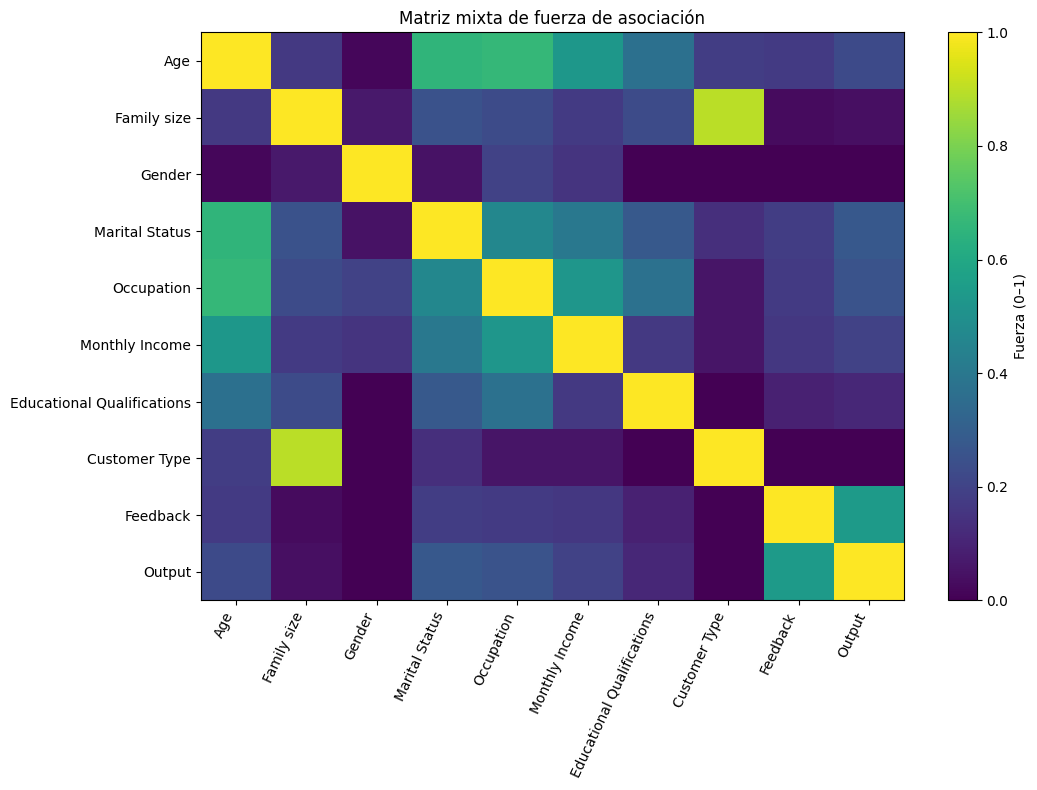

,variable_1,variable_2,fuerza
14,Family size,Customer Type,0.8960
3,Age,Occupation,0.6670
2,Age,Marital Status,0.6560
44,Feedback,Output,0.5460
4,Age,Monthly Income,0.5290
30,Occupation,Monthly Income,0.5240
24,Marital Status,Occupation,0.4620
25,Marital Status,Monthly Income,0.3990
31,Occupation,Educational Qualifications,0.3730
5,Age,Educational Qualifications,0.3690


In [14]:
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(assoc.values, vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(assoc.columns)))
ax.set_yticks(range(len(assoc.index)))
ax.set_xticklabels(assoc.columns, rotation=65, ha='right')
ax.set_yticklabels(assoc.index)
ax.set_title('Matriz mixta de fuerza de asociación')
fig.colorbar(im, ax=ax, label='Fuerza (0–1)')
plt.tight_layout()
plt.show()

pares = []
for i, a in enumerate(vars_mixtas):
    for b in vars_mixtas[i+1:]:
        pares.append({'variable_1': a, 'variable_2': b, 'fuerza': assoc.loc[a,b]})
pares = pd.DataFrame(pares).sort_values('fuerza', ascending=False)
display(pares.head(15).round(3))

### Hallazgo estructural importante

La matriz revela relaciones fuertes entre variables explicativas. Esto importa porque un patrón con `Output` puede estar reflejando otra característica relacionada.

En particular:

- `Age` está fuertemente relacionada con `Occupation` y `Marital Status`.
- `Occupation` y `Monthly Income` también están estrechamente asociadas.
- `Family size` y `Customer Type` muestran una relación extremadamente fuerte.

Por eso no es correcto leer cada porcentaje segmentado como si las variables fueran independientes entre sí.

## 12. Comprobación de posible redundancia: `Family size` vs `Customer Type`

Una asociación muy alta merece inspección directa. La tabla cruzada permite saber si se trata simplemente de una correlación fuerte o de una estructura casi determinista del dataset.

In [15]:
family_customer = pd.crosstab(df['Family size'], df['Customer Type'])
display(family_customer)

print('\nResumen de Family size por Customer Type:')
display(df.groupby('Customer Type')['Family size'].agg(['count','mean','median','min','max']).round(3))

Customer Type,Frequent,New,Regular
Family size,,,
1,0,18,0
2,0,0,75
3,0,0,87
4,45,0,0
5,37,0,0
6,23,0,0



Resumen de Family size por Customer Type:


,count,mean,median,min,max
Customer Type,,,,,
Frequent,105,4.7900,5.0000,4,6
New,18,1.0000,1.0000,1,1
Regular,162,2.5370,3.0000,2,3


### Interpretación

En esta muestra, los grupos quedan completamente separados por tamaño de familia:

- `New`: Family size = 1;
- `Regular`: Family size = 2–3;
- `Frequent`: Family size = 4–6.

Esto **sugiere una variable construida o una fuerte redundancia de diseño**, aunque el archivo por sí solo no permite demostrar cómo fue creada. Para modelado o interpretación causal no convendría tratarlas como dos señales totalmente independientes.

## 13. Relación numérica-numérica: Spearman

Spearman mide relaciones monotónicas y es apropiada cuando no queremos asumir linealidad ni normalidad. Solo se aplica a las variables numéricas conceptuales (`Age` y `Family size`); los códigos postales no son magnitudes numéricas.

In [16]:
rho, p_s = spearmanr(df['Age'], df['Family size'])
print(f'Spearman Age vs Family size: rho={rho:.3f}, p={p_s:.4g}')

Spearman Age vs Family size: rho=0.167, p=0.004753


## 14. Variables geográficas: verificar redundancia antes de analizar

`Pin code`, `latitude` y `longitude` describen localización. Antes de calcular cualquier correlación se comprueba si el código postal identifica exactamente a un par de coordenadas.

In [17]:
max_lat_por_pin = df.groupby('Pin code')['latitude'].nunique().max()
max_lon_por_pin = df.groupby('Pin code')['longitude'].nunique().max()
max_pin_por_coord = df.groupby(['latitude','longitude'])['Pin code'].nunique().max()

print('Máximo número de latitudes por Pin code:', max_lat_por_pin)
print('Máximo número de longitudes por Pin code:', max_lon_por_pin)
print('Máximo número de Pin codes por par lat/lon:', max_pin_por_coord)
print('Pin codes únicos:', df['Pin code'].nunique())
print('Pares lat/lon únicos:', df[['latitude','longitude']].drop_duplicates().shape[0])

Máximo número de latitudes por Pin code: 1
Máximo número de longitudes por Pin code: 1
Máximo número de Pin codes por par lat/lon: 1
Pin codes únicos: 77
Pares lat/lon únicos: 77


### Interpretación geográfica

En este archivo cada `Pin code` corresponde exactamente a un par de coordenadas y viceversa. Son tres representaciones de la misma dimensión geográfica, por lo que introducir las tres como variables independientes generaría redundancia.

Para Power BI sí tiene sentido conservar latitud/longitud para mapas y `Pin code` como etiqueta o filtro, pero estadísticamente deben entenderse como la misma localización.

## 15. Regresión logística exploratoria: análisis ajustado

Las pruebas anteriores son **bivariadas**: analizan una variable a la vez contra `Output`. Sin embargo, `Age`, `Occupation`, `Marital Status` e `Income` están relacionadas entre sí.

Para comprobar si algunos patrones permanecen al ajustar por otras variables, se utiliza una regresión logística parsimoniosa con:

- `Feedback`;
- `Age`;
- `Marital Status`;
- `Occupation`.

No incluimos simultáneamente todas las variables porque la muestra es pequeña y algunas son muy redundantes. Este modelo es **exploratorio**, no un modelo causal ni una validación predictiva.

In [18]:
df_modelo = df.copy()
df_modelo['Output_bin'] = (df_modelo['Output']=='Yes').astype(int)

try:
    import statsmodels.formula.api as smf
    modelo = smf.logit(
        "Output_bin ~ Age + C(Feedback) + C(Q('Marital Status')) + C(Occupation)",
        data=df_modelo
    ).fit(disp=False)

    ci = modelo.conf_int()
    tabla_or = pd.DataFrame({
        'OR': np.exp(modelo.params),
        'IC95_inf': np.exp(ci[0]),
        'IC95_sup': np.exp(ci[1]),
        'p_value': modelo.pvalues,
    })
    print(f'Pseudo R² de McFadden: {modelo.prsquared:.3f}')
    print(f'LLR p-value global: {modelo.llr_pvalue:.3g}')
    display(tabla_or.round(4))
except ImportError:
    print('statsmodels no está instalado. El resto del análisis sigue siendo válido.')

Pseudo R² de McFadden: 0.289
LLR p-value global: 1e-16


,OR,IC95_inf,IC95_sup,p_value
Intercept,0.2363,0.0032,17.5213,0.5114
C(Feedback)[T.Positive],16.0880,7.6126,33.9994,0.0000
C(Q('Marital Status'))[T.Prefer not to say],0.6939,0.1284,3.7508,0.6712
C(Q('Marital Status'))[T.Single],2.1229,0.7945,5.6724,0.1333
C(Occupation)[T.House wife],1.9428,0.2720,13.8798,0.5080
C(Occupation)[T.Self Employeed],1.1563,0.4350,3.0735,0.7710
C(Occupation)[T.Student],2.0915,0.7780,5.6221,0.1436
Age,0.9914,0.8519,1.1538,0.9114


### Interpretación del modelo ajustado

En la muestra actual, **Feedback positivo sigue siendo el predictor con evidencia más clara** al ajustar simultáneamente por edad, estado civil y ocupación. Su odds ratio es muy superior a 1.

En cambio, los efectos bivariados de edad, estado civil y ocupación se atenúan y dejan de ser estadísticamente claros en este modelo. Esto es una señal importante: parte de sus asociaciones simples con `Output` probablemente comparte estructura con otras variables del dataset.

No debe interpretarse el OR como “feedback positivo causa pedidos”. El dataset solo permite hablar de asociación.

## 16. Resumen estadístico de los insights principales

Con los **285 registros únicos** del archivo actual:

1. **Output está desbalanceado hacia `Yes`**: aproximadamente 76% de las observaciones únicas son `Yes`.
2. **Feedback es la señal más fuerte**: `Positive` presenta cerca de 87% de `Yes`, mientras `Negative` ronda 28%. La diferencia es de ~60 puntos porcentuales y V de Cramér corregida es ~0.55.
3. **Edad presenta una diferencia bivariada**: el grupo `Yes` es, en promedio, alrededor de 1.6 años más joven; Mann–Whitney es significativo y el tamaño de efecto rank-biserial es moderado.
4. **Estado civil, ocupación e ingreso mensual tienen asociaciones bivariadas significativas**, incluso tras la corrección de Holm; sin embargo, están relacionadas entre sí y con edad.
5. **Gender, Customer Type y Educational Qualifications no muestran evidencia suficiente de relación con Output** en esta muestra bajo las pruebas utilizadas.
6. **Family size no tiene relación bivariada relevante con Output**, pero está casi completamente ligada a `Customer Type`; esto es una advertencia de redundancia.
7. **Pin code, latitude y longitude representan la misma localización** en este dataset, por lo que no deben tratarse como tres señales independientes.
8. En el **modelo logístico ajustado**, Feedback conserva una asociación fuerte, mientras los otros efectos se debilitan. Este resultado hace que Feedback sea el insight más robusto del análisis exploratorio.

## 17. Qué NO podemos concluir

Para evitar sobreinterpretación:

- No podemos afirmar que un feedback positivo **cause** `Output = Yes`.
- No podemos afirmar que ser estudiante o soltero cause una mayor respuesta `Yes`.
- No debemos interpretar los porcentajes de categorías con muy pocos registros como estimaciones estables.
- No debemos considerar `Customer Type` y `Family size` independientes en esta muestra.
- No debemos tratar `Pin code` como una variable continua solo porque sea numérica.

Estas restricciones son parte del análisis estadístico y deben aparecer también en una presentación profesional.

## 18. Recomendaciones para Power BI a partir del análisis mejorado

Para el dashboard principal priorizaría:

- **KPIs:** registros únicos, % Yes, % feedback positivo, edad media.
- **Visual principal:** tasa de Yes por Feedback.
- **Segmentación secundaria:** estado civil, ocupación e ingreso, mostrando siempre el tamaño de muestra.
- **Mapa:** coordenadas con `Pin code` como etiqueta/filtro, no como medida continua.
- **Tooltip de confiabilidad:** incluir `n` por segmento para evitar que categorías pequeñas parezcan igual de confiables.
- **Página técnica:** V de Cramér, p-value ajustado Holm, rank-biserial y matriz mixta de asociaciones.

La historia central del dashboard debería ser: **Feedback es la relación más consistente con Output; varios patrones demográficos existen de forma bivariada, pero están entrelazados y se debilitan al analizarlos de manera conjunta.**